<a href="https://colab.research.google.com/github/NETSADOM/Alx_DjangoLearnLab/blob/main/Support_Vector_Machine_(SVM)_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [71]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

In [72]:
x,y = make_blobs(n_samples=100, centers=2, cluster_std=3.5, random_state=42)
x.shape, y.shape, x[:5], y[:5]

((100, 2),
 (100,),
 array([[-4.18630746,  8.36447971],
        [ 8.43055819,  5.66147687],
        [-4.41453716,  9.40251519],
        [ 7.5170894 ,  8.61194512],
        [ 5.43598861,  6.54816932]]),
 array([0, 1, 0, 1, 1]))

In [73]:
y=y*2. - 1
y[:10]

array([-1.,  1., -1.,  1.,  1., -1.,  1.,  1., -1., -1.])

In [74]:
np.random.seed(42)
w= np.random.rand(2,)
b=np.random.rand()
w,b

(array([0.37454012, 0.95071431]), 0.7319939418114051)

In [75]:
def predict(x,w,b):
  m=x.shape[0]
  y_pred=np.zeros(m)
  for i in range(m):
    y_pred[i]=np.dot(x[i],w)+b
  y_pred = np.sign(y_pred)
  return y_pred

In [76]:
predict(x[:10],w,b)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [77]:
def plot_true_vs_pred(X, y, w, b):

    # limit plot display horizontally and vertically
    xlim = np.array([x[:,0].min()-1, x[:,0].max()+1])
    ylim = np.array([x[:,1].min()-1, x[:,1].max()+1])

    # y_true plot
    plt.figure(figsize=(4,3))
    plt.scatter(x[:,0][y==-1], x[:,1][y==-1], c='r', label='y=-1')
    plt.scatter(x[:,0][y==1], x[:,1][y==1], c='b', label='y=-1')
    plt.title("y_true")
    plt.xlim(xlim[0], xlim[1])
    plt.ylim(ylim[0], ylim[1])


    # y_preds plot
    plt.figure(figsize=(4,3))
    y_pred = predict(x, w, b)
    plt.scatter(x[:,0][y_pred==-1], x[:,1][y_pred==-1], c='red', label='y=-1')
    plt.scatter(x[:,0][y_pred==1], x[:,1][y_pred==1], c='blue', label='y=1')
    plt.title("y_pred")
    plt.xlim(xlim[0], xlim[1])
    plt.ylim(ylim[0], ylim[1])

    # decision boundary & margin
    xx = xlim
    yyn = (-1 - b - (w[0] * xx)) / w[1]
    yym =     (-b - (w[0] * xx)) / w[1]
    yyp =  (1 - b - (w[0] * xx)) / w[1]

    plt.plot(xx, yyn, color='red', linestyle='dotted')
    plt.plot(xx, yym, color='black')
    plt.plot(xx, yyp, color='blue', linestyle='dotted')




In [78]:
def calc_hinge_loss(X_i, y_i, w, b):
    return max(0, 1 - y_i * (np.dot(w, X_i) + b))

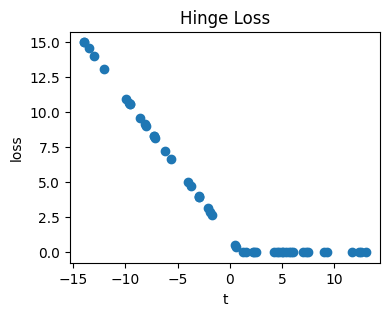

In [79]:
n_examples = 50
t = np.zeros(n_examples)
loss = np.zeros(n_examples)

for i in range(n_examples):
    t[i] = y[i] * (np.dot(w, x[i]) + b)
    loss[i] = calc_hinge_loss(x[i], y[i], w, b)

plt.figure(figsize=(4,3))
plt.scatter(t, loss)
plt.title("Hinge Loss")
plt.xlabel("t")
plt.ylabel("loss")
plt.show()

In [80]:
def calc_cost(x, y, w, b, C=1):
    m = x.shape[0]

    margin_cost = (np.dot(w, w) ** 2) / 2

    hinge_cost = 0
    for i in range(m):
        loss_i = calc_hinge_loss(x[i], y[i], w, b)
        hinge_cost += loss_i
    hinge_cost *= C

    total_cost = margin_cost + hinge_cost
    return total_cost

In [81]:
calc_cost(x, y, w, b)

np.float64(442.79701081354773)

In [82]:
def calc_gradient(x, y, w, b, C=1):
    n = x.shape[1]
    m = x.shape[0]

    dj_dw = np.zeros(n)
    dj_db = 0.

    for i in range(m):
        hinge_condition = (1 - y[i] * (np.dot(w, x[i]) + b)) > 0
        if hinge_condition:
            dj_dw -= (C * y[i] * x[i])
            dj_db -= C * y[i]

    dj_dw += w

    return dj_dw, dj_db

In [83]:
dj_dw, dj_db = calc_gradient(x, y, w, b)
dj_dw, dj_db

(array([-177.25171872,  443.32580276]), np.float64(44.0))

In [84]:
alpha = 0.001
w_new = w - alpha * dj_dw
b_new = b - alpha * dj_db

print(f"Before: {calc_cost(x, y, w, b)}")
print(f"After: {calc_cost(x, y, w_new, b_new)}")

Before: 442.79701081354773
After: 217.3486638430651


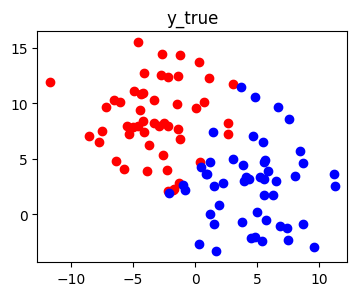

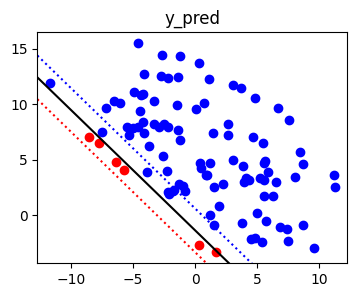

In [85]:
plot_true_vs_pred(x,y,w_new, b_new)

In [86]:
def gradient_descent(x, y, w, b, n_iters=1000, C=1, alpha=0.001, history_step=100):
    history = {}

    for iter in range(n_iters):
        dj_dw, dj_db = calc_gradient(x, y, w, b, C)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        if iter % 100 == 0:
            cost = calc_cost(x, y, w, b, C)
            print(f"Iter\t{iter}\tCost\t{cost}")
            history[iter] = cost

    return history, w, b

In [87]:
history, w_new, b_new = gradient_descent(x, y, w, b)

Iter	0	Cost	217.3486638430651
Iter	100	Cost	14.557816414370718
Iter	200	Cost	14.282185732594739
Iter	300	Cost	14.027063786483785
Iter	400	Cost	13.795150673884391
Iter	500	Cost	13.660520126639724
Iter	600	Cost	13.567521967684494
Iter	700	Cost	13.490917616889124
Iter	800	Cost	13.407136066198731
Iter	900	Cost	13.33838956957736


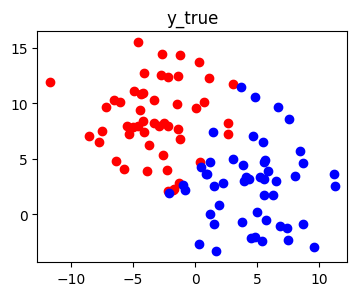

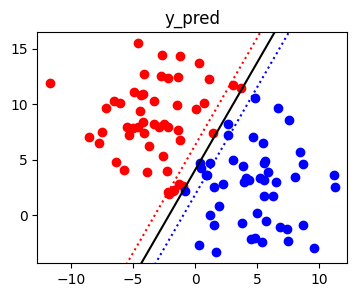

In [88]:
plot_true_vs_pred(x, y, w_new, b_new)

In [89]:
def plot_history(history):
    plt.figure(figsize=(4,3))
    plt.plot(history.keys(), history.values())
    plt.title("Cost over Iterations")
    plt.xlabel("Iteration")
    plt.ylabel("Cost")

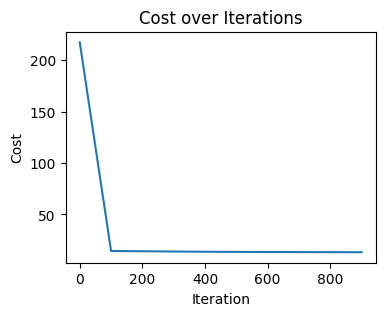

In [90]:
plot_history(history)